<a href="https://colab.research.google.com/github/HyeonnWoo/26-2-DIP-202001601/blob/main/HW01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
imgpath = '/content/drive/MyDrive/Medical_Imaging/DIP4E/DIP4E'

**실습코드 00**

In [89]:
from PIL import Image
from PIL.ExifTags import TAGS

In [90]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.9 MB/s eta 0:00:00


In [91]:
!pip install nibabel

In [92]:
import nibabel as nib

In [94]:
ct_FU = nib.load('volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load('volume-covid19-A-0700_day015_regist.nii.gz').get_fdata()

In [98]:
h = nib.load('volume-covid19-A-0700_day000.nii.gz')
ct_base = h.get_fdata()

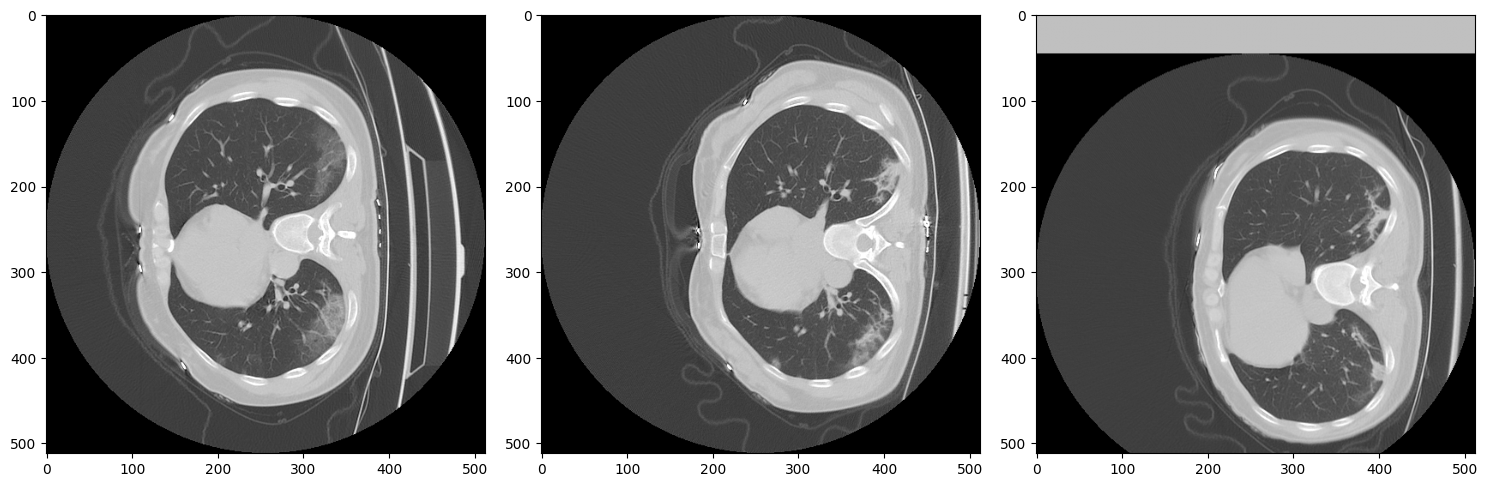

In [99]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

**실습코드 01**

In [ ]:
def histogram_equalization(image):    # 모든 값들이 비슷한 값을 가지게 (equalization)
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image  #각각의 line code가 의미하는 바를 확인

In [ ]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


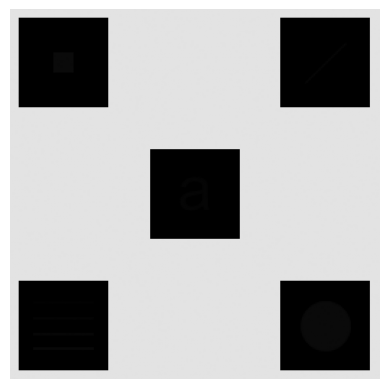

In [ ]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

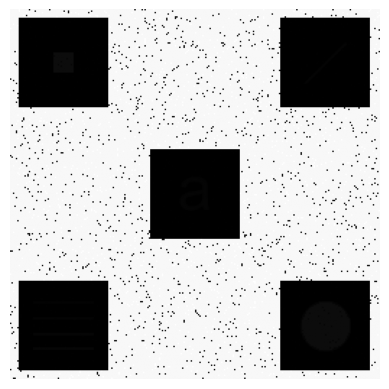

In [ ]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

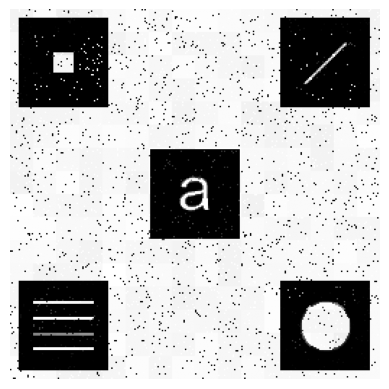

In [ ]:
N = 16
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()
# N = 16 : 왼쪽 상단 정사각형, 오른쪽 상단 대각선, 가운데 소문자 영어 a, 왼쪽 하단 선분 4개, 오른쪽 하단 원

**실습코드 02**

In [39]:
import scipy.signal as signal
from skimage import io

In [45]:
f = io.imread(imgpath+'/IMG_1012.jpg', as_gray=True)
print(f.shape,f.dtype)

(4032, 2268) float64


In [46]:
import time

computation time =  0.48339390754699707  sec


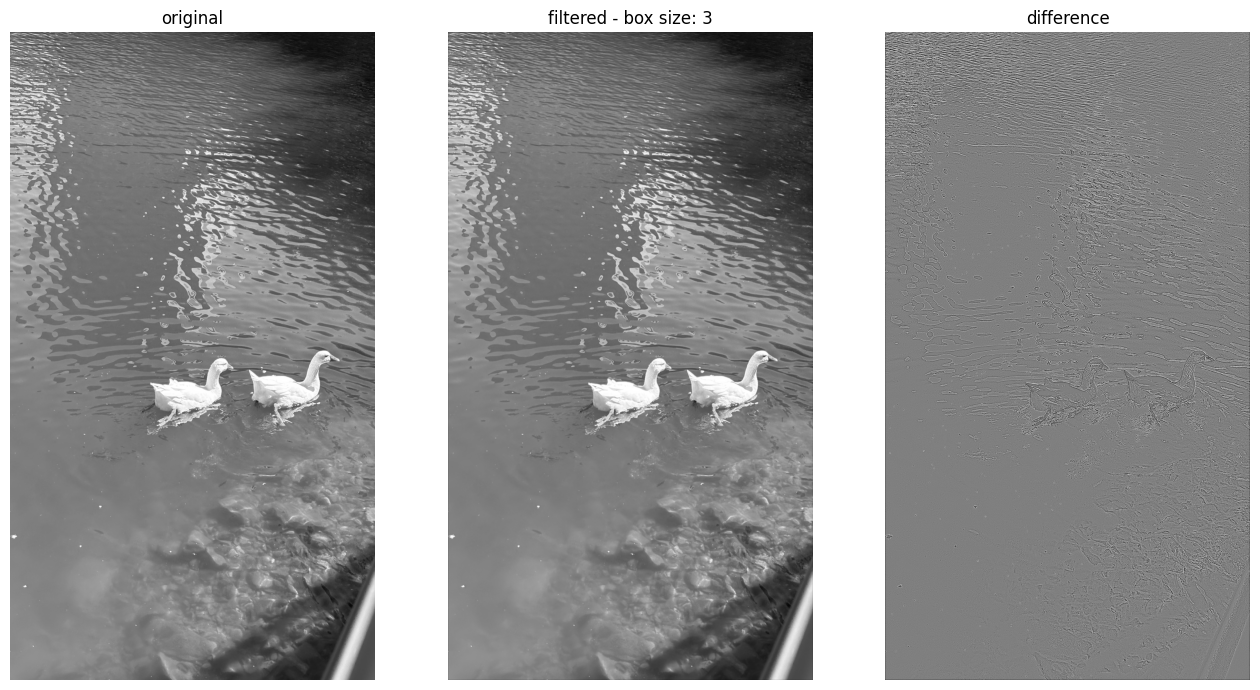

computation time =  2.7951183319091797  sec


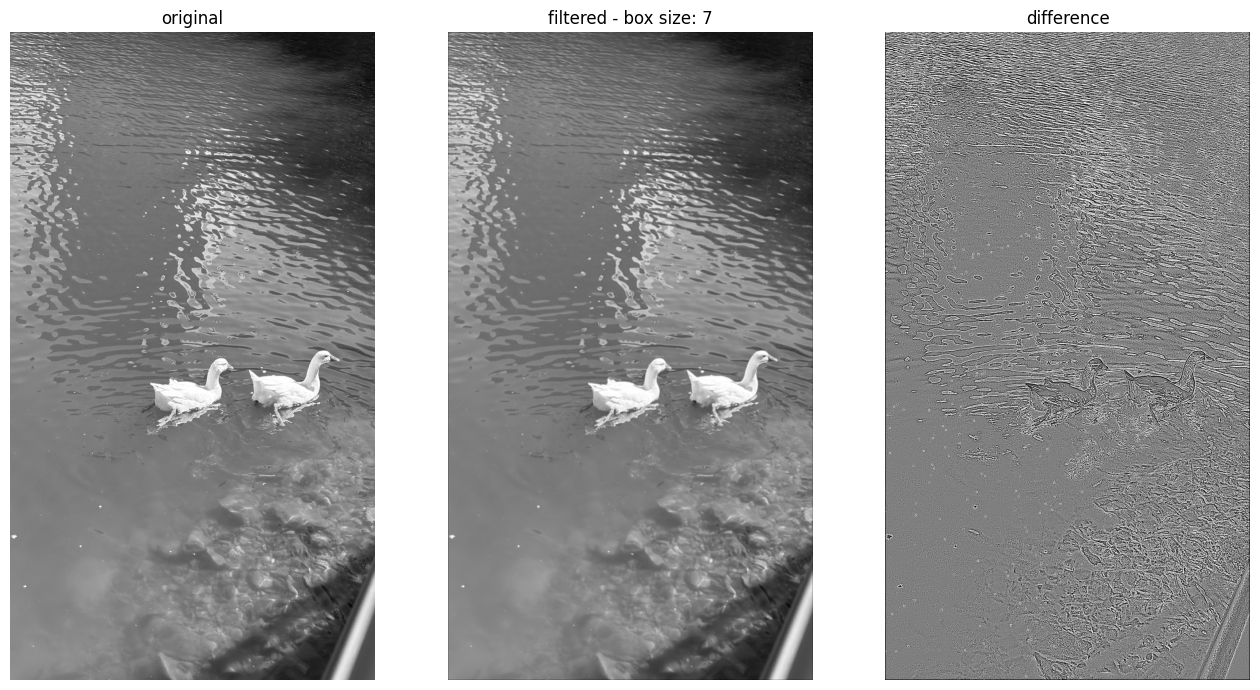

computation time =  5.299987316131592  sec


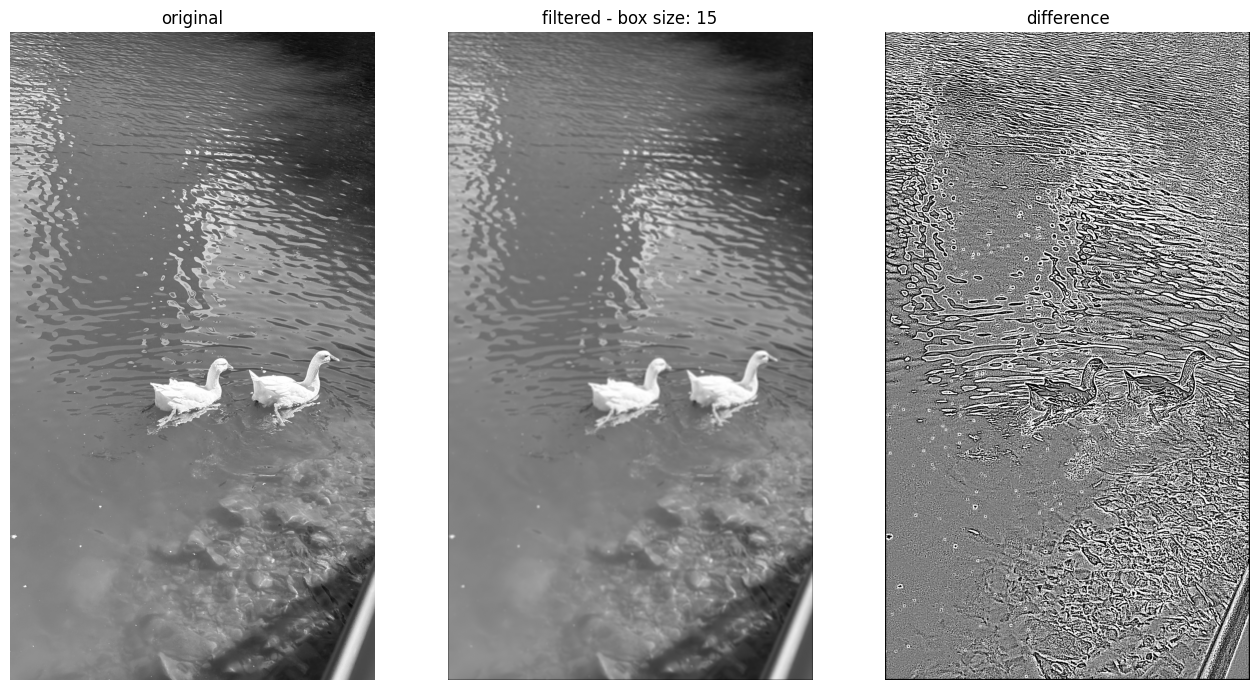

computation time =  25.825247526168823  sec


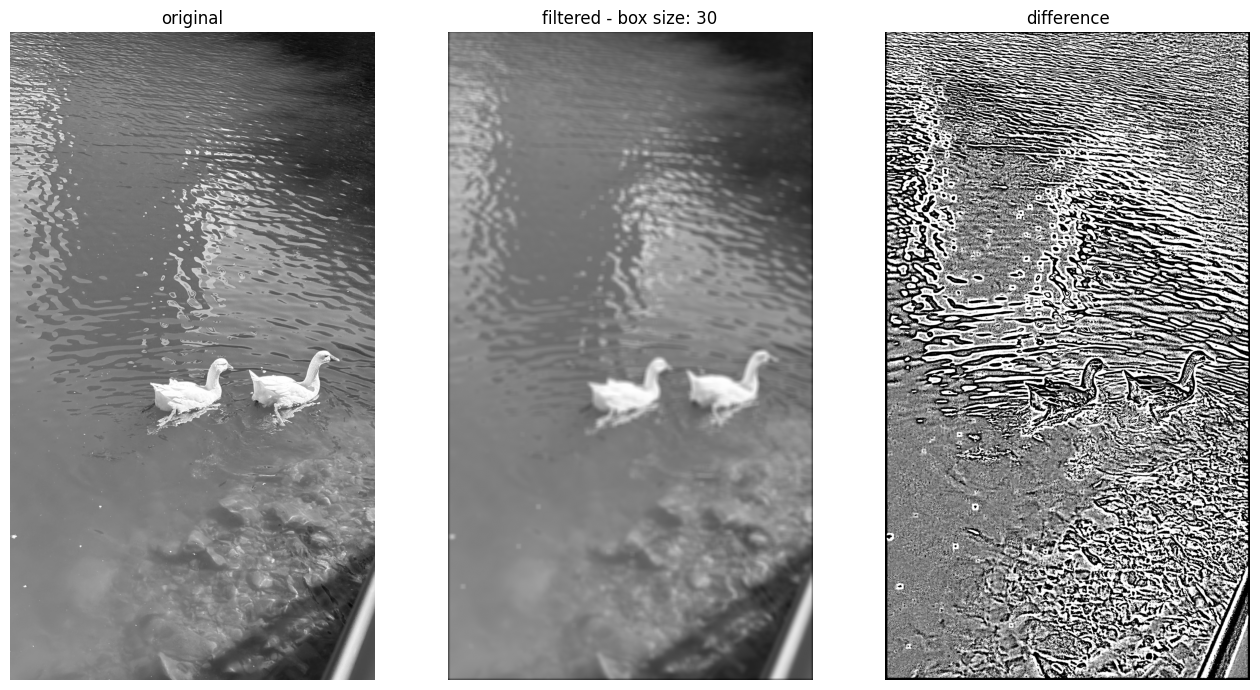

In [47]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

**실습코드 03**

In [76]:
import cv2
import os
from PIL import Image
# cv2 opencv를 사용하여 blur image 생성

In [77]:
src = cv2.imread(imgpath+'/IMG_1012.jpg')
dst = cv2.blur(src, (50, 50))

In [78]:
cv2.imwrite('blurred_IMG.jpg', dst)

True

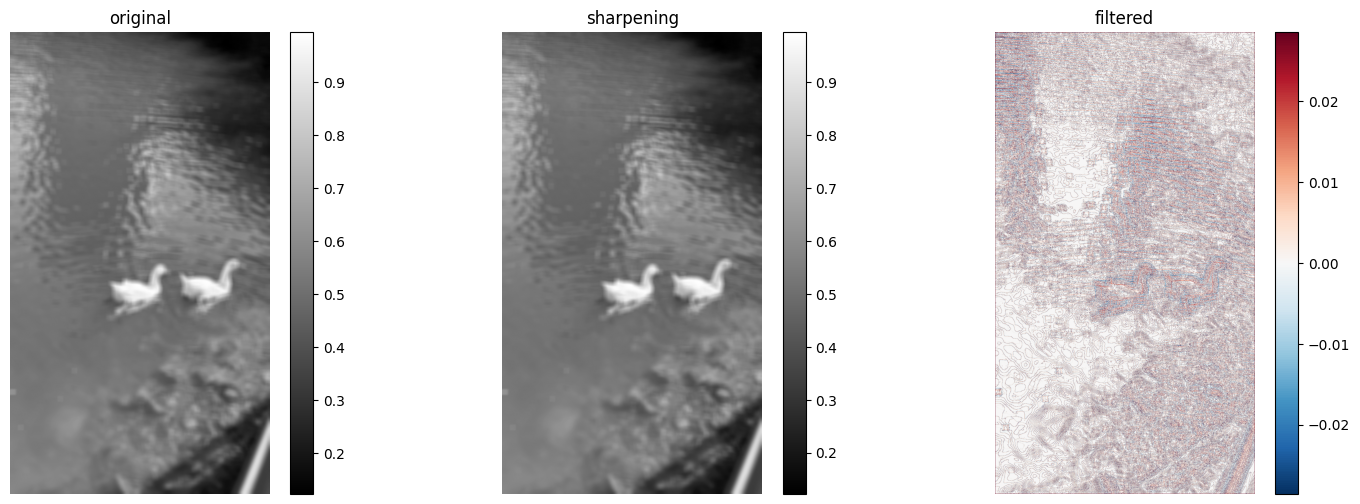

In [119]:
f = io.imread(os.path.join(imgpath+'/blurred_IMG.jpg'),as_gray=True)[::2,::2]

w = np.array([[0,-2,0],[-2,8.,-2],[0,-2,0]])
y = signal.convolve2d(f,w,mode='same')
c = 0.01234
g = f + c*(y)
plt.figure(figsize=(18,6))

plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')

plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')

plt.subplot(133)
lim = np.percentile(np.abs(y[1:-1, 1:-1]), 99) # y의 픽셀값 범위 수정
plt.imshow(y,cmap='RdBu_r',vmin=-lim,vmax=lim)#,vmin=-np.max(np.abs(y)),vmax=np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

In [120]:
sobel1 = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
sobel2 = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(sobel1)
print(sobel2)

[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


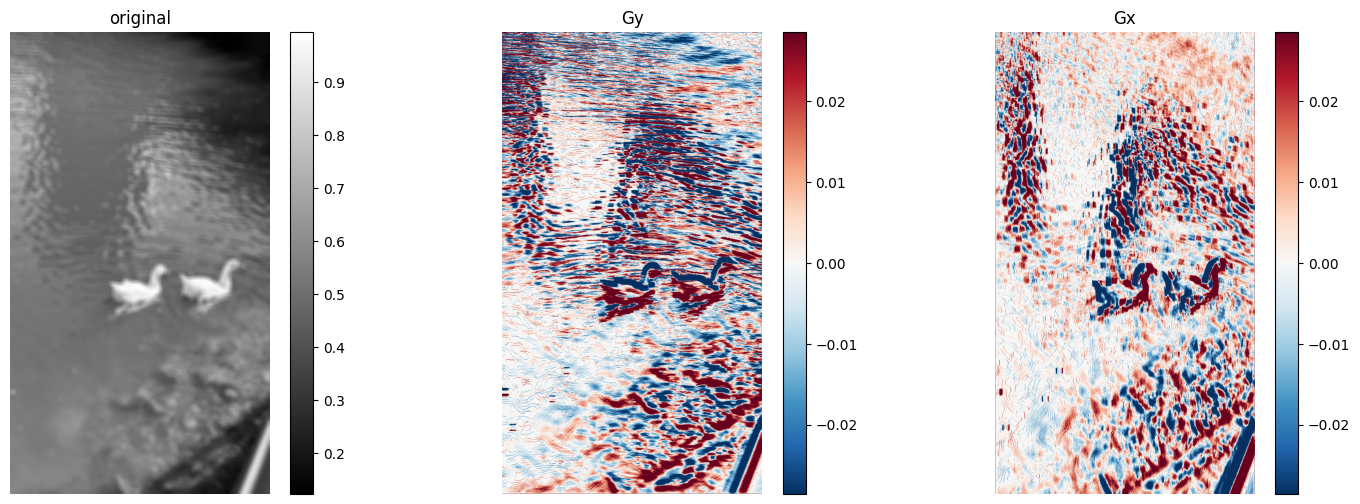

In [122]:
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g1,cmap='RdBu_r',vmin=-lim,vmax=lim)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(133)
plt.imshow(g2,cmap='RdBu_r',vmin=-lim,vmax=lim)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.show()

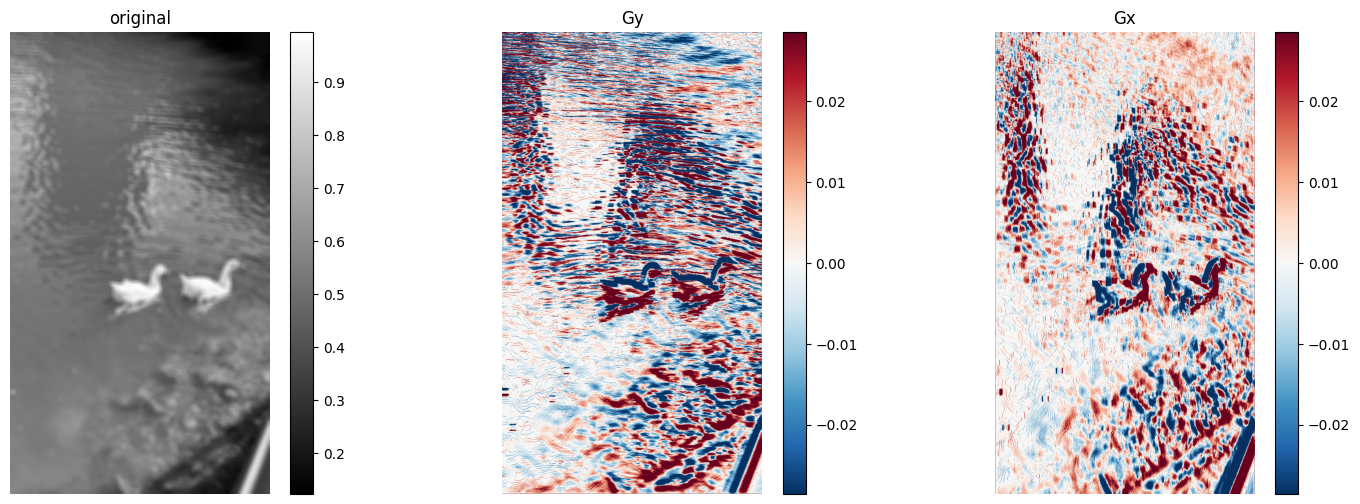

In [123]:
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g1,cmap='RdBu_r',vmin=-lim,vmax=lim)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(133)
plt.imshow(g2,cmap='RdBu_r',vmin=-lim,vmax=lim)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.show()
